# David calibrado fijo + CO₂ disuelto con saturación térmica

Comparación sin recalibración en LAB019–021: David original entrega directamente $q_{prod}=\dot E$; su extensión conserva esa misma producción y añade:
\[
\dot C_d=q_{prod}-q_{gas},\qquad q_{gas}=k_La\max(C_d-C_{sat}(T),0).
\]
No se modifica la química, el reparto de nitrógeno ni la nutrición de David. Se carga exclusivamente su ajuste guardado en `configs/models/david_2012/fit.json`. Sin activación empírica, ganancia de sensor ni filtrado de predicciones. La ley de transferencia es una hipótesis adicional de sobresaturación, no una ecuación original de David ni una consecuencia obligada de Henry.

## Solubilidad y supuestos

Se usa la dependencia térmica de la correlación de Lonvaud-Funel y Matsumoto reproducida por Liger-Belair et al. (2023), ecuación 1, [DOI](https://doi.org/10.1021/acsomega.3c01812). Para aislar temperatura se fija composición de referencia a=12.5 % vol de etanol, b=0 g/L de azúcar. El coeficiente térmico es $7\times10^{-5}a-0.02905=-0.028175$ °C⁻¹. Se ancla la solubilidad a 1.5 g/L/bar a 20 °C:
\[
C_{sat}(T)=1.5\exp[-0.028175(T-20)]\ p_{CO_2}.
\]
**Es una aproximación de vino de referencia, no una correlación validada para nuestro mosto durante toda la fermentación.** No se aplican efectos de E ni S para no añadir cambios simultáneos. La temperatura procede del log, en °C en esta correlación.

$p_{CO_2}=1$ bar constante es un supuesto de ensayo de gas rico en CO₂, no una medición ni un cálculo de composición del espacio de cabeza. No se simula el vaciado de ese espacio ni el transporte por mangueras. $C_d(0)=0$ en todos los casos, como política acordada; se distingue de las estimaciones experimentales de CO₂ inicial.

**No se calibra ningún parámetro.** Se comparan kLa=0.07, 2 y 20 h⁻¹ en figuras separadas. La figura principal corresponde a 2 h⁻¹ como referencia de ensayo; no se afirma que sea el coeficiente físico del recipiente. 0.07 es sólo una sensibilidad y no reproduce Zenteno, porque aquí el coeficiente actúa en otra ecuación.

El volumen parte de 2 L y descuenta las muestras, incluida muestra 1; no aumenta por nutrición. La retirada homogénea conserva Cd y retira masa V·Cd. Se comprueban conservación y positividad. La comparación experimental utiliza medianas horarias de RAW convertida con volumen remanente. Se puntúa toda la cobertura común y también se informa error censurado para valores inferiores a 0.05 g/(L·h); no se utilizan esos errores para ajustar.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.david_2012.empirical import build,NAMES
from wine_fermentation.models.david_2012 import kinetics as david
from wine_fermentation.models.david_2012_dissolved import co2 as dissolved
protected=[p for folder in ('src','configs','notebooks') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and 'david_2012_dissolved' not in str(p)]
def hashes():return {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
before=hashes()
fit=json.loads((ROOT/'configs/models/david_2012/fit.json').read_text())
parameters=build([fit['parameters'][k] for k in NAMES])
LABS=['LAB019','LAB020','LAB021'];K_VALUES=[.07,2.,20.];MAIN_K=2.
display(pd.DataFrame({'T_C':[12,16,18,20,21,25],'Csat_g_L':dissolved.saturation([12,16,18,20,21,25])}))


,T_C,Csat_g_L
0,12,1.879236
1,16,1.678944
2,18,1.586952
3,20,1.500000
4,21,1.458327
5,25,1.302897


In [2]:
from dataclasses import replace
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
v=load(ROOT)
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h'])
co2_observations=observations(raw)
validation={}
for lab in ['LAB019','LAB020','LAB021']:
 b=v.batches[lab];ev=raw[(raw.lab==lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h')
 et=ev.time_h.to_numpy();vol=ev.remaining_volume_L.to_numpy()
 def volume(t):return np.r_[2.,vol][np.searchsorted(et,np.asarray(t),side='right')]
 initial=dict(X=b.initials['X'],N=b.initials['N'],S=b.initials['G']+b.initials['F'],E=b.initials['E'])
 s=chemical_observations(v.chem,lab,'GF');s0=s[s.t_h.le(0)]
 if len(s0):initial['S']=float(s0.GF_g_l.iloc[-1])
 events=tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])
 validation[lab]=david.simulate(b.time,b.temperature_c,initial,events,parameters)
print('LAB019–021 leídos después del ajuste. Predicciones sin reajuste.')


LAB019–021 leídos después del ajuste. Predicciones sin reajuste.


In [3]:
contexts={};gas={};metrics=[];balances=[]
for lab in LABS:
 b=v.batches[lab];core=validation[lab]
 ev=raw[(raw.lab==lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h')
 et=ev.time_h.to_numpy();vol=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vol=vol):return np.r_[2.,vol][np.searchsorted(et,np.asarray(t),side='right')]
 volume.knots=et
 contexts[lab]=(b,volume)
 for k in K_VALUES:
  f=dissolved.simulate(core,b.time,b.temperature_c,volume,kLa=k,Cd0=0.)
  gas[k,lab]=f
  h=np.diff(f.index);cd=f.Cd.to_numpy();V=f.V.to_numpy()
  prod=float(np.sum(h*f.qprod.to_numpy()[:-1]));emitted=float(np.sum(h*f.qgas.to_numpy()[1:]))
  removed=float(np.sum(cd[1:]*(V[:-1]-V[1:])))
  mass_error=V[-1]*cd[-1]-V[0]*cd[0]-np.sum(V[:-1]*h*(f.qprod.to_numpy()[:-1]-f.qgas.to_numpy()[1:]))+removed
  assert abs(prod-emitted-(cd[-1]-cd[0]))<1e-8
  assert abs(mass_error)<1e-8
  fine=dissolved.simulate(core,b.time,b.temperature_c,volume,kLa=k,Cd0=0.,step=.0125)
  o=co2_observations[lab];o=o[o.time_h.between(core.index[0],core.index[-1])]
  numerical_rms=float(np.sqrt(np.mean((np.interp(o.time_h,f.index,f.qgas)-np.interp(o.time_h,fine.index,fine.qgas))**2)))
  balances.append(dict(lab=lab,kLa=k,produced_g_L=prod,emitted_g_L=emitted,Cd_final=cd[-1],Csat_min=f.Csat.min(),Csat_max=f.Csat.max(),V_initial=V[0],V_final=V[-1],withdrawn_dissolved_g=removed,mass_error_g=mass_error,numerical_rms_g_L_h=numerical_rms,source_integral_minus_David_E=prod-(core.E.iloc[-1]-core.E.iloc[0])))
 for label,t,y in [('David directo',core.index,core.qCO2)]+[(f'Cd · kLa={k:g}',gas[k,lab].index,gas[k,lab].qgas) for k in K_VALUES]:
  o=co2_observations[lab];o=o[o.time_h.between(core.index[0],core.index[-1])]
  pred=np.interp(o.time_h,t,y);error=pred-o.co2_raw_g_l_h.to_numpy()
  censored=np.where(o.co2_raw_g_l_h.to_numpy()<.05,np.maximum(pred-.05,0),error)
  # Identical observed time interval and hourly-median AUC convention for all comparisons.
  area_obs=np.trapz(o.co2_raw_g_l_h,o.time_h);area_pred=np.trapz(pred,o.time_h)
  metrics.append(dict(lab=lab,model=label,RMSE=np.sqrt(np.mean(error**2)),bias=error.mean(),censored_RMSE=np.sqrt(np.mean(censored**2)),area_pred_g_L=area_pred,area_observed_g_L=area_obs,initial_q=float(np.asarray(y)[0]),peak_q=float(np.max(y)),peak_h=float(np.asarray(t)[np.argmax(y)])))
display(pd.DataFrame(metrics).round(5))
display(pd.DataFrame(balances).round(7))


,lab,model,RMSE,bias,censored_RMSE,area_pred_g_L,area_observed_g_L,initial_q,peak_q,peak_h
0,LAB019,David directo,0.23208,0.17833,0.22844,72.73939,39.98857,0.15877,1.07383,73.16667
1,LAB019,Cd · kLa=0.07,0.22093,0.16985,0.21491,71.24416,39.98857,0.00000,0.86228,83.08333
2,LAB019,Cd · kLa=2,0.22932,0.17083,0.22678,71.44068,39.98857,0.00000,1.07500,73.16667
3,LAB019,Cd · kLa=20,0.22837,0.16967,0.22567,71.22706,39.98857,0.00000,1.10575,72.83333
4,LAB020,David directo,0.23165,0.19785,0.22208,72.54814,36.19670,0.11157,1.00223,79.91667
5,LAB020,Cd · kLa=0.07,0.21727,0.18462,0.20800,70.11172,36.19670,0.00000,0.81784,91.95000
6,LAB020,Cd · kLa=2,0.22759,0.18881,0.21949,70.94326,36.19670,0.00000,1.00742,82.16667
7,LAB020,Cd · kLa=20,0.22717,0.18791,0.21906,70.77829,36.19670,0.00000,1.04146,80.16667
8,LAB021,David directo,0.24120,0.18564,0.22728,74.26334,40.16883,0.13331,1.25148,54.83333
9,LAB021,Cd · kLa=0.07,0.29286,0.17586,0.27856,72.51732,40.16883,0.00000,0.97124,63.20000


,lab,kLa,produced_g_L,emitted_g_L,Cd_final,Csat_min,Csat_max,V_initial,V_final,withdrawn_dissolved_g,mass_error_g,numerical_rms_g_L_h,source_integral_minus_David_E
0,LAB019,0.07,72.894960,71.244225,1.650735,1.441984,1.808165,1.95,1.7,1.951623,0.0,0.000099,0.010168
1,LAB019,2.00,72.894960,71.452927,1.442033,1.441984,1.808165,1.95,1.7,0.454575,0.0,0.000316,0.010168
2,LAB019,20.00,72.894960,71.452976,1.441984,1.441984,1.808165,1.95,1.7,0.396360,-0.0,0.000839,0.010168
3,LAB020,0.07,72.569553,70.116094,2.453458,1.572364,1.693196,1.95,1.7,1.853047,0.0,0.000087,0.007341
4,LAB020,2.00,72.569553,70.986747,1.582806,1.572364,1.693196,1.95,1.7,0.472556,-0.0,0.000204,0.007341
5,LAB020,20.00,72.569553,70.987433,1.582119,1.572364,1.693196,1.95,1.7,0.421267,-0.0,0.000493,0.007341
6,LAB021,0.07,74.308979,72.518644,1.790334,1.441984,1.585214,1.95,1.7,2.101097,0.0,0.000112,0.009440
7,LAB021,2.00,74.308979,72.739801,1.569178,1.441984,1.585214,1.95,1.7,0.436256,-0.0,0.000281,0.009440
8,LAB021,20.00,74.308979,72.739812,1.569167,1.441984,1.585214,1.95,1.7,0.381032,0.0,0.000329,0.009440


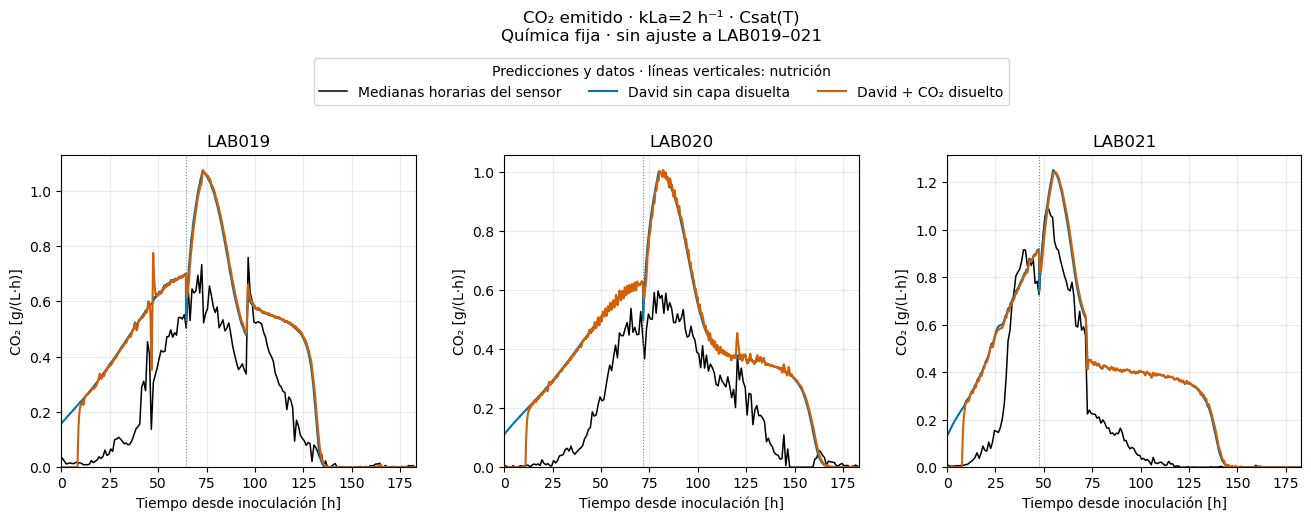

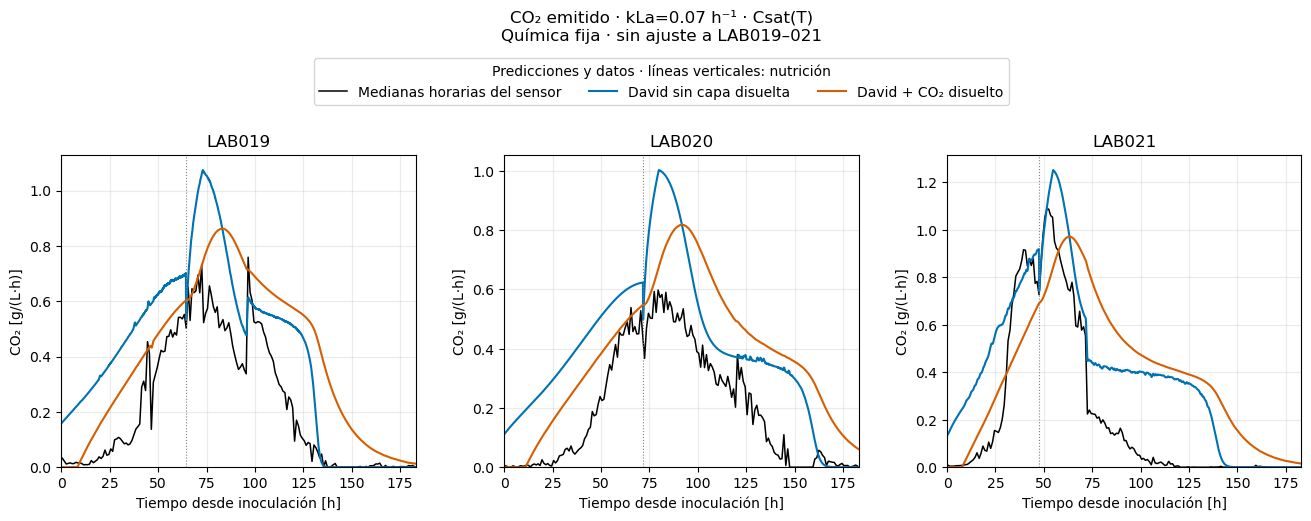

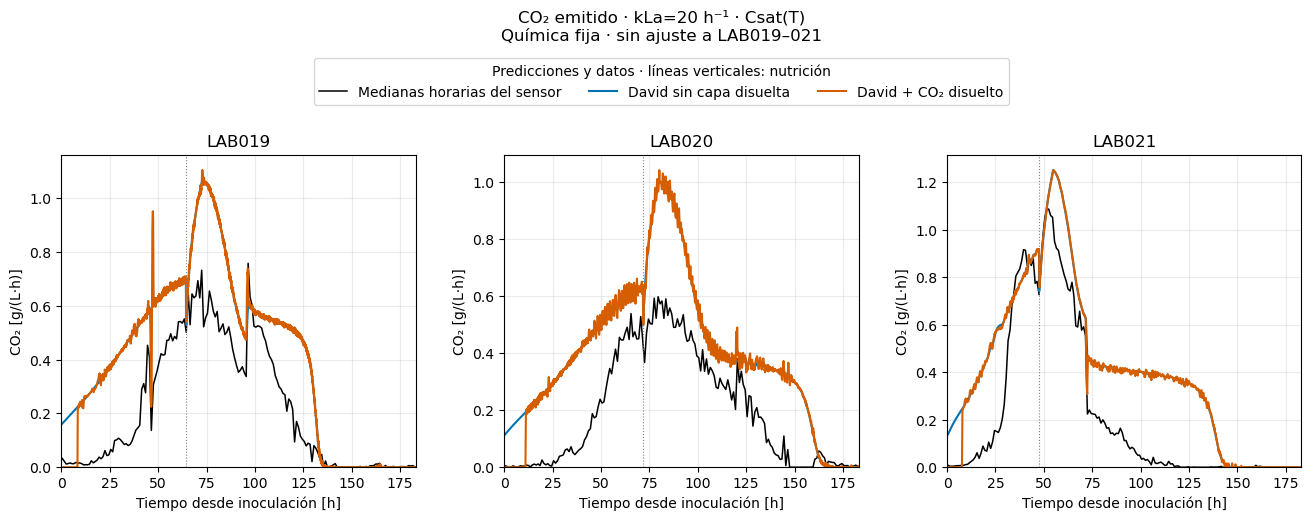

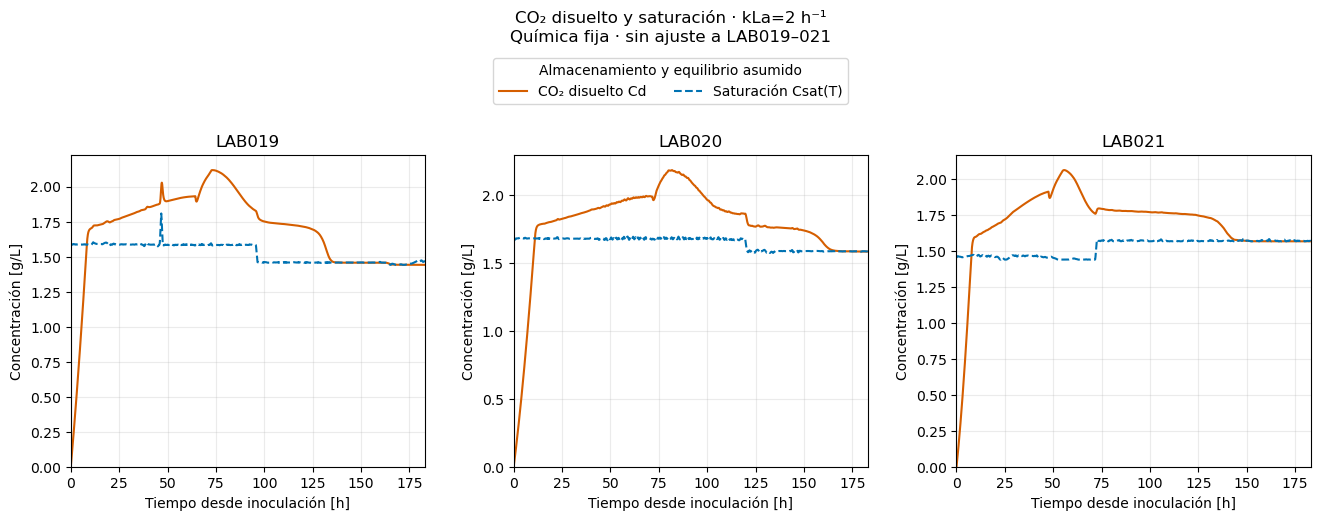

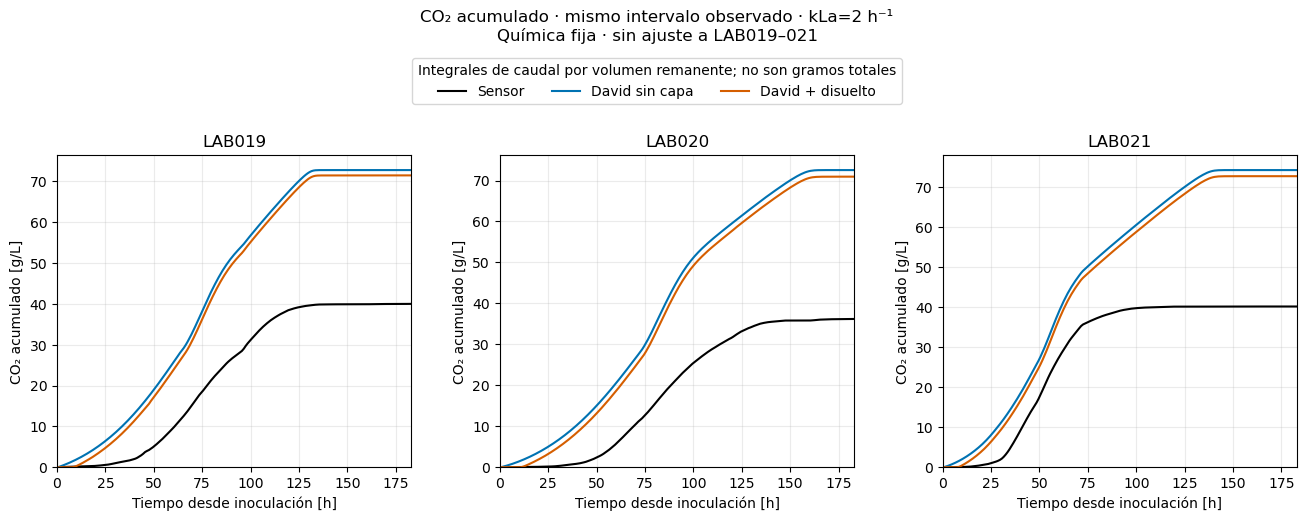

Verificado: química y ajuste de David originales intactos; sin optimización, ganancia, filtro ni exportaciones CSV/PNG.


In [4]:
def panel_figure(title):
 fig,axes=plt.subplots(1,3,figsize=(16,5.2))
 fig.suptitle(title+'\nQuímica fija · sin ajuste a LAB019–021',y=.99)
 fig.subplots_adjust(top=.71,wspace=.25)
 return fig,axes
for k in [MAIN_K,.07,20.]:
 fig,axes=panel_figure(f'CO₂ emitido · kLa={k:g} h⁻¹ · Csat(T)')
 for ax,lab in zip(axes,LABS):
  core=validation[lab];f=gas[k,lab];o=co2_observations[lab]
  ax.plot(o.time_h,o.co2_raw_g_l_h,color='black',lw=1.1,label='Medianas horarias del sensor')
  ax.plot(core.index,core.qCO2,color='#0072B2',label='David sin capa disuelta')
  ax.plot(f.index,f.qgas,color='#D55E00',label='David + CO₂ disuelto')
  for ti,d in v.batches[lab].pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
  ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/(L·h)]',xlim=(0,core.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.91),ncol=3,title='Predicciones y datos · líneas verticales: nutrición')
 plt.show()
fig,axes=panel_figure('CO₂ disuelto y saturación · kLa=2 h⁻¹')
for ax,lab in zip(axes,LABS):
 f=gas[MAIN_K,lab]
 ax.plot(f.index,f.Cd,label='CO₂ disuelto Cd',color='#D55E00')
 ax.plot(f.index,f.Csat,label='Saturación Csat(T)',color='#0072B2',ls='--')
 ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel='Concentración [g/L]',xlim=(0,f.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.91),ncol=2,title='Almacenamiento y equilibrio asumido')
plt.show()
fig,axes=panel_figure('CO₂ acumulado · mismo intervalo observado · kLa=2 h⁻¹')
for ax,lab in zip(axes,LABS):
 o=co2_observations[lab];core=validation[lab];o=o[o.time_h.between(0,core.index[-1])];t=o.time_h.to_numpy()
 for label,rate,color in [('Sensor',o.co2_raw_g_l_h.to_numpy(),'black'),('David sin capa',np.interp(t,core.index,core.qCO2),'#0072B2'),('David + disuelto',np.interp(t,gas[MAIN_K,lab].index,gas[MAIN_K,lab].qgas),'#D55E00')]:
  integral=np.r_[0.,np.cumsum(np.diff(t)*(rate[:-1]+rate[1:])/2)]
  ax.plot(t,integral,label=label,color=color)
 ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ acumulado [g/L]',xlim=(0,core.index[-1]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.91),ncol=3,title='Integrales de caudal por volumen remanente; no son gramos totales')
plt.show()
assert hashes()==before,'Cambió un archivo original protegido'
print('Verificado: química y ajuste de David originales intactos; sin optimización, ganancia, filtro ni exportaciones CSV/PNG.')


## Cómo interpretar esta prueba

La capa disuelta permite producción biológica antes de que salga gas. Una vez sobrepasada la saturación, el caudal depende del exceso de Cd y de kLa. Al bajar T, sube Csat; al subir T puede liberarse parte del inventario. La sobresaturación dinámica implica que Cd puede ser mayor que Csat, no un fallo de integración.

La química de X, YAN, S y E es idéntica para todos los escenarios por construcción. Cualquier cambio en el CO₂ se debe exclusivamente a almacenamiento y liberación. No se ha hecho una nueva validación química ni una nueva calibración.

La diferencia entre producción y emisión debe permanecer en Cd o salir disuelta en muestras. Esta capa no puede eliminar la diferencia de área previamente detectada. Las tablas separan el balance conservativo por pasos del AUC trapezoidal sobre medianas horarias: las diferencias de cuadratura no son pérdida física de CO₂. También se informa la diferencia entre la integral de la fuente interpolada y el incremento de E del integrador de David.


## Resultado del ensayo

Con kLa=2 h⁻¹, el RMSE cambia de 0.23208 a 0.22932 en LAB019, de 0.23165 a 0.22759 en LAB020 y de 0.24120 a 0.23835 g/(L·h) en LAB021. La emisión arranca en cero, pero después se acerca rápidamente a la producción directa. No se ha identificado kLa con estos resultados.

El AUC observado es aproximadamente 39.99, 36.20 y 40.17 g/L; la extensión principal predice 71.44, 70.94 y 72.74 g/L en el mismo soporte horario. Permanece la discrepancia de cantidades. El depósito termina con 1.44, 1.58 y 1.57 g/L disueltos; no retiene decenas de g/L.

Con kLa=0.07 h⁻¹ se suavizan los picos: mejoran LAB019–020, pero empeora LAB021 (RMSE 0.29286). Con kLa=20 se sigue más rápidamente la producción. Las pequeñas fluctuaciones térmicas pueden producir variaciones de Csat y del caudal; no se ha filtrado la predicción.

Los balances conservativos de concentración y masa, incluidas retiradas, se cumplen a tolerancia numérica. Dividir el paso por dos produce diferencias RMS de caudal inferiores a 0.00084 g/(L·h) en los escenarios probados. La discrepancia entre integral de la fuente interpolada e incremento de E es menor que 0.011 g/L. Nada de esto resuelve la incertidumbre física de presión, solubilidad de mosto o coeficiente de transferencia.
